In [1]:
from Bio import SeqIO
from Bio import pairwise2
from Bio.pairwise2 import align, format_alignment
from collections import Counter
from Bio.SeqUtils import gc_fraction, molecular_weight as mw, MeltingTemp as mt 
from Levenshtein import hamming, distance
import matplotlib.pyplot as plt

c:\Users\Zhvn\AppData\Local\Programs\Python\Python310\lib\site-packages\Bio\pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


In [ ]:
# 1. Sequence Manipulation
# a. Tampilkan panjang Sequence A dan Sequence B.
seqA = SeqIO.read("a1.fasta", "fasta").seq
seqB = SeqIO.read("b1.fasta", "fasta").seq

lenA = len(seqA)
lenB = len(seqB)
totalLen = lenA + lenB

print("Panajng Sequence A: ", lenA)
print("Panjang Sequence B: ", lenB)
print("Total Panjang Sequence A dan B: ", totalLen)

# b. Cari indeks kemunculan pertama motif "GTA" pada sequence A dan B
print(f"Index the first time codon (GTA) appears in sequence A: {seqA.index('GTA')}")
print(f"Index the first time codon (GTA) appears in sequence B: {seqB.index('GTA')}")

# c. Ambil 12 nukleotida pertama dari Sequence A dan 18 nukleotida terakhir dari Sequence B, lalu gabingkan menjadi sequence C
seqC = seqA[:12] + seqB[-18:]
print("Sequence C: ", seqC)
print(f"Reverse Sequecne C: {seqC[::-1]}")

Panajng Sequence A:  84
Panjang Sequence B:  85
Total Panjang Sequence A dan B:  169
Index the first time codon (GTA) appears in sequence A: 4
Index the first time codon (GTA) appears in sequence B: 5
Sequence C:  ATGCGTACGTTACTAGCGATCGTACGATGC
Reverse Sequecne C: CGTAGCATGCTAGCGATCATTGCATGCGTA


A = Counter({'G': 24, 'T': 21, 'A': 20, 'C': 19}), B = Counter({'G': 23, 'C': 21, 'A': 21, 'T': 20}), C = Counter({'T': 8, 'G': 8, 'A': 7, 'C': 7})


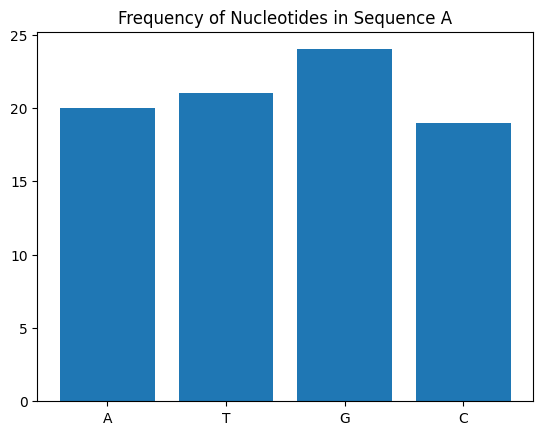

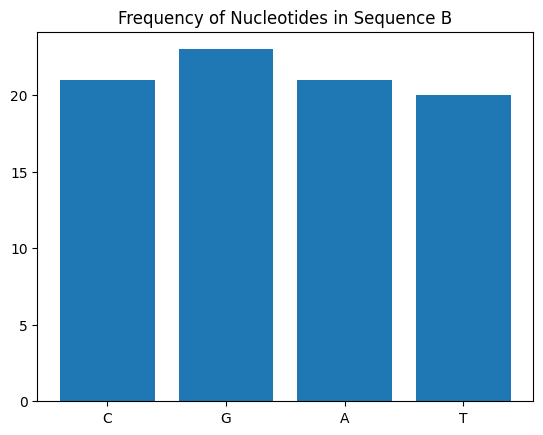

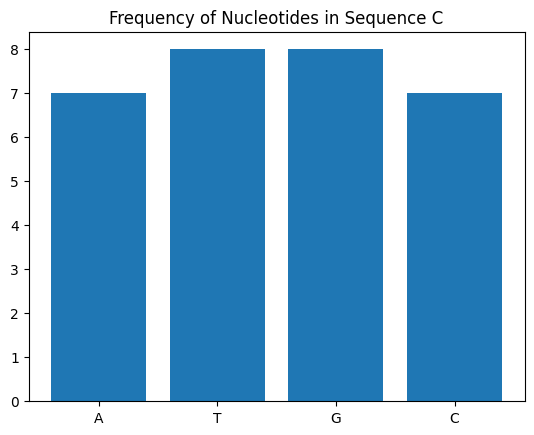

GC Content Sequence A: 51.19%
AT Content Sequence A: 48.81%
GC Content Sequence B: 51.76%
AT Content Sequence B: 48.24%
GC Content Sequence C: 50.00%
AT Content Sequence C: 50.00%
Melting Temperature Sequence A: 254.00°C
Melting Temperature Sequence B: 258.00°C
Melting Temperature Sequence C: 90.00°C
Molecular Weight Sequence A: 26065.60 g/mol
Molecular Weight Sequence B: 26323.77 g/mol
Molecular Weight Sequence C: 9301.93 g/mol


In [16]:
# 2. Sequence Analysis & Plotting
# a. Hitung frequensi basa A, G, C, T pada sequence A, B, dan C. Visualisasikan menggunakan matplotlib
CountA = Counter(seqA)
CountB = Counter(seqB)
CountC = Counter(seqC)

print(f"A = {CountA}, B = {CountB}, C = {CountC}")

plt.bar(CountA.keys(), CountA.values())
plt.title("Frequency of Nucleotides in Sequence A")
plt.show()

plt.bar(CountB.keys(), CountB.values())
plt.title("Frequency of Nucleotides in Sequence B")
plt.show()

plt.bar(CountC.keys(), CountC.values())
plt.title("Frequency of Nucleotides in Sequence C")
plt.show()

# b. Hitung GC Content dan AT Content untuk sequence A, B dan C
gcA = gc_fraction(seqA)*100
print(f"GC Content Sequence A: {gcA:.2f}%")
print(f"AT Content Sequence A: {(100-gcA):.2f}%")

gcB = gc_fraction(seqB)*100
print(f"GC Content Sequence B: {gcB:.2f}%")
print(f"AT Content Sequence B: {(100-gcB):.2f}%")

gcC = gc_fraction(seqC)*100
print(f"GC Content Sequence C: {gcC:.2f}%")
print(f"AT Content Sequence C: {(100-gcC):.2f}%")

# c. Hitung Melting Temperature menggunakan Wallace Rule untuk sequence A, B dan C
tmA = mt.Tm_Wallace(seqA)
print(f"Melting Temperature Sequence A: {tmA:.2f}°C")

tmB = mt.Tm_Wallace(seqB)
print(f"Melting Temperature Sequence B: {tmB:.2f}°C")

tmC = mt.Tm_Wallace(seqC)
print(f"Melting Temperature Sequence C: {tmC:.2f}°C")

# d. Hitung Molecular Weight untuk sequence A, B dan C
mwA = mw(seqA)
print(f"Molecular Weight Sequence A: {mwA:.2f} g/mol")

mwB = mw(seqB)
print(f"Molecular Weight Sequence B: {mwB:.2f} g/mol")

mwC = mw(seqC)
print(f"Molecular Weight Sequence C: {mwC:.2f} g/mol")

In [17]:
# 3. DNA > mRNA > Protein
# a. Transkripsikan Sequence A, B, dan C menjadi mRNA
mrnaA = seqA.transcribe()
print("mRNA Sequence A: ", mrnaA)

mrnaB = seqB.transcribe()
print("mRNA Sequence B: ", mrnaB)

mrnaC = seqC.transcribe()
print("mRNA Sequence C: ", mrnaC)

# b. Terjemahkan mRNA menjadi amino acid sequence
aminoA = mrnaA.translate()
print("Amino Acid Sequence A: ", aminoA)

aminoB = mrnaB.translate()
print("Amino Acid Sequence B: ", aminoB)

aminoC = mrnaC.translate()
print("Amino Acid Sequence C: ", aminoC)


mRNA Sequence A:  AUGCGUACGUUAGCGAUCGAUCGUACGUAGCUAGCUAGCGUACGUAGCUAACGUUAGCGAUCGAUGCUAGCUAGCGUACGAUCG
mRNA Sequence B:  CGAUCGUACGUAGCUAGCAUCGAUGCUAGCUAGCGAUCGUACGAUCGAUCGUAGCUAGCUAACGUAGCUAGCGAUCGUACGAUGC
mRNA Sequence C:  AUGCGUACGUUACUAGCGAUCGUACGAUGC
Amino Acid Sequence A:  MRTLAIDRT*LASVRS*R*RSMLASVRS
Amino Acid Sequence B:  RSYVASIDAS*RSYDRS*LANVASDRTM
Amino Acid Sequence C:  MRTLLAIVRC


c:\Users\Zhvn\AppData\Local\Programs\Python\Python310\lib\site-packages\Bio\Seq.py:2874: BiopythonWarning: Partial codon, len(sequence) not a multiple of three. Explicitly trim the sequence or add trailing N before translation. This may become an error in future.
  warnings.warn(


In [21]:
# 4. Alignment & Similarity
# a. Lakukan local alignment antara Sequence A dan Sequence B
localAlignments = align.localxx(seqA, seqB)
for alignment in localAlignments:
    print(format_alignment(*alignment))

# b. Lakukan global alignment antara Sequence A dan Sequence B
globalAlignments = align.globalxx(seqA, seqB)
for alignment in globalAlignments:
    print(format_alignment(*alignment))

# c. Hitung Hamming Distance dan Levenshtein Distance antara Sequence A dan Sequence B
hammingDist = hamming(str(seqA), str(seqB))
levenshteinDist = distance(str(seqA), str(seqB))
print(f"Hamming Distance between Sequence A and B: {hammingDist}")
print(f"Levenshtein Distance between Sequence A and B: {levenshteinDist}")
    

1 ATGCGTACGTTAGCGATC-G-ATCGTACGTAGCTAGCTAGCGTA-CGTAGCTA-A-CG-T--TAGCG-A--T--CGAT-GCTAGCTAG--CGTACGATCG
  || |||||| ||||  |  | |||| |  | ||||||||||| | |||| |   | || |  ||||  |  |  || | ||||||  |  |||||||| |
3 AT-CGTACG-TAGC--T-AGCATCG-A--T-GCTAGCTAGCG-ATCGTA-C--GATCGATCGTAGC-TAGCTAACG-TAGCTAGC--GATCGTACGAT-G
  Score=66

1 ATGCGTACGTTAGCGATC-G-ATCGTACGTAGCTAGCTAGCGTA-CGTAGCTA-A-CG-T--TAGCG-A--T--CGAT-GCTAGCTAG--CGTACGATCG
  || ||||||| |||  |  | |||| |  | ||||||||||| | |||| |   | || |  ||||  |  |  || | ||||||  |  |||||||| |
3 AT-CGTACGT-AGC--T-AGCATCG-A--T-GCTAGCTAGCG-ATCGTA-C--GATCGATCGTAGC-TAGCTAACG-TAGCTAGC--GATCGTACGAT-G
  Score=66

1 ATGCGTACGTTAGCGATCG-ATCGTACGTAGCTAGCTAGCGTA-CGTAGCTA-A-CG-T--TAGCG-A--T--CGAT-GCTAGCTAG--CGTACGATCG
  || |||||| ||||  |.| |||| |  | ||||||||||| | |||| |   | || |  ||||  |  |  || | ||||||  |  |||||||| |
3 AT-CGTACG-TAGC--TAGCATCG-A--T-GCTAGCTAGCG-ATCGTA-C--GATCGATCGTAGC-TAGCTAACG-TAGCTAGC--GATCGTACGAT-G
  Score=66

1 ATGCGTACGTTAGCGATCG-ATCGTACGTAGCTAGCTA